# Chọn số cụm K: phương pháp Elbow và chỉ số Silhouette

*Bài 8, mục 8.1.3.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

# Dữ liệu 21 điểm của giáo trình (Chương 11)
x1 = np.array([3, 1, 1, 2, 1, 6, 6, 6, 5, 6, 7, 8, 9, 8, 9, 9, 8, 4, 4, 5, 4])
x2 = np.array([5, 4, 5, 6, 5, 8, 6, 7, 6, 7, 1, 2, 1, 2, 3, 2, 3, 9, 10, 9, 10])
X = np.column_stack([x1, x2]).astype(float)

## 1. Phương pháp Elbow

Chạy K-means với nhiều giá trị $K$, tính:
- **Inertia** (WSS – within-cluster sum of squares): $\mathcal{L}(K) = \sum_i \|\mathbf{x}_i - \boldsymbol{\mu}_{c_i}\|^2$;
- **Distortion**: trung bình bình phương khoảng cách tới tâm gần nhất, $\mathcal{L}(K)/N$.

Giá trị tối ưu toàn cục $\mathcal{L}^*(K)$ không tăng khi $K$ tăng (bằng 0 khi $K = N$). Các lần chạy Lloyd hữu hạn có thể không giảm đều do khởi tạo và nghiệm cục bộ khác nhau; cần chạy nhiều khởi tạo trước khi so sánh. Chọn $K$ tại "khuỷu tay", nơi tốc độ giảm chậm hẳn lại.

K = 1: inertia =  312.95, distortion = 14.902
K = 2: inertia =  108.07, distortion = 5.146
K = 3: inertia =   39.52, distortion = 1.882
K = 4: inertia =   17.98, distortion = 0.856
K = 5: inertia =   14.45, distortion = 0.688
K = 6: inertia =   11.52, distortion = 0.548
K = 7: inertia =    9.08, distortion = 0.433
K = 8: inertia =    6.83, distortion = 0.325
K = 9: inertia =    6.67, distortion = 0.317


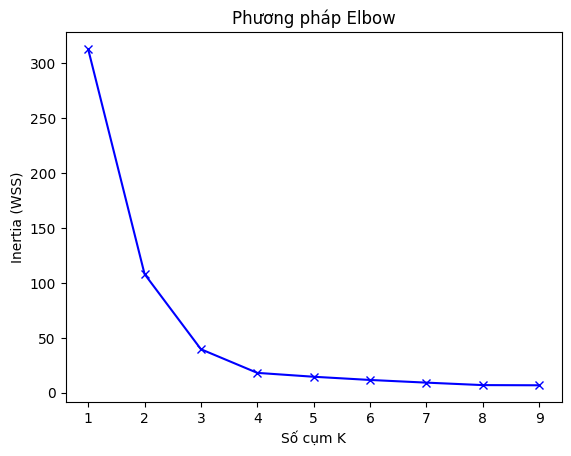

In [2]:
K_values = range(1, 10)
inertias, distortions = [], []
for k in K_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(model.inertia_)
    distortions.append(np.sum(np.min(cdist(X, model.cluster_centers_, 'euclidean'), axis=1)**2) / len(X))
    print('K = %d: inertia = %7.2f, distortion = %.3f' % (k, inertias[-1], distortions[-1]))

plt.plot(K_values, inertias, 'bx-')
plt.xlabel('Số cụm K'); plt.ylabel('Inertia (WSS)'); plt.title('Phương pháp Elbow')
plt.show()

Mức giảm của inertia khi tăng K thêm 1:

In [3]:
drops = -np.diff(inertias)
for k, drop in zip(range(2, 10), drops):
    print('K = %d -> %d: giảm %.2f' % (k - 1, k, drop))

K = 1 -> 2: giảm 204.88
K = 2 -> 3: giảm 68.55
K = 3 -> 4: giảm 21.54
K = 4 -> 5: giảm 3.53
K = 5 -> 6: giảm 2.93
K = 6 -> 7: giảm 2.43
K = 7 -> 8: giảm 2.25
K = 8 -> 9: giảm 0.17


## 2. Chỉ số Silhouette

Với mỗi điểm $\mathbf{x}_i$:
- $a(i)$: khoảng cách trung bình tới các điểm **khác** trong cùng cụm;
- $b(i)$: khoảng cách trung bình nhỏ nhất tới các điểm của một cụm khác (cụm gần nhất);
- $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))} \in [-1, 1]$.

Tính tay cho một điểm với $K = 4$:

In [4]:
model = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
labels = model.labels_
i = 0                                          # điểm (3, 5)
own = labels[i]
distances = np.linalg.norm(X - X[i], axis=1)
a = distances[(labels == own) & (np.arange(len(X)) != i)].mean()
b = min(distances[labels == k].mean() for k in set(labels) if k != own)
print('Điểm', X[i], 'thuộc cụm', own)
print('a(i) = %.3f, b(i) = %.3f, s(i) = %.3f' % (a, b, (b - a) / max(a, b)))

from sklearn.metrics import silhouette_samples, silhouette_score
print('silhouette_samples cho điểm này: %.3f' % silhouette_samples(X, labels)[i])

Điểm [3. 5.] thuộc cụm 2
a(i) = 1.913, b(i) = 3.370, s(i) = 0.433
silhouette_samples cho điểm này: 0.433


Chỉ số Silhouette của cả tập là trung bình $s(i)$. Chọn $K$ có Silhouette lớn nhất ($K \ge 2$).

In [5]:
scores = []
for k in range(2, 10):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores.append(silhouette_score(X, labels))
    print('K = %d: silhouette = %.3f' % (k, scores[-1]))
print('K tốt nhất theo Silhouette:', 2 + int(np.argmax(scores)))

K = 2: silhouette = 0.592
K = 3: silhouette = 0.652
K = 4: silhouette = 0.675
K = 5: silhouette = 0.625
K = 6: silhouette = 0.463
K = 7: silhouette = 0.430


K = 8: silhouette = 0.433
K = 9: silhouette = 0.371
K tốt nhất theo Silhouette: 4


## 3. Quan sát kết quả phân cụm với các giá trị K khác nhau

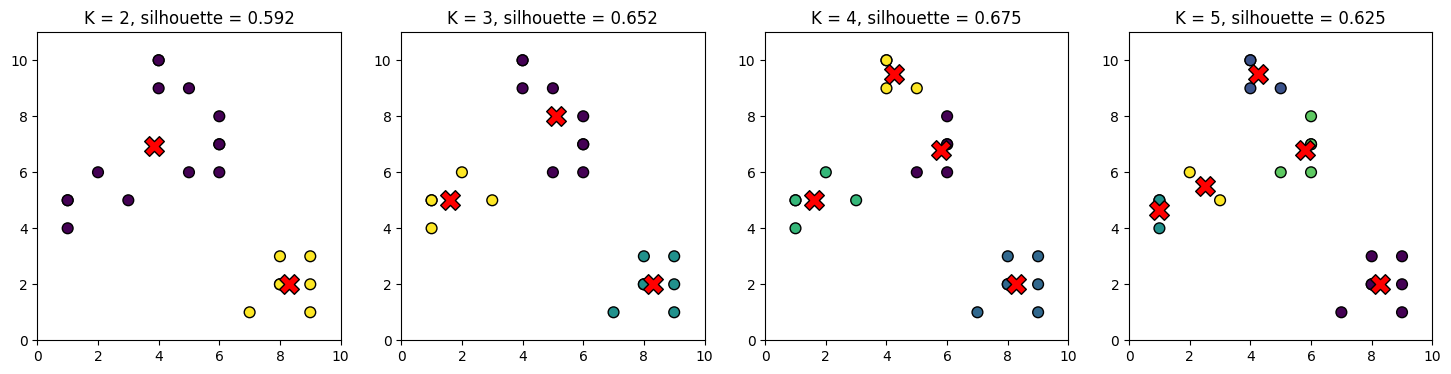

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, [2, 3, 4, 5]):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    ax.scatter(X[:, 0], X[:, 1], c=model.labels_, cmap='viridis', s=60, edgecolors='k')
    ax.scatter(*model.cluster_centers_.T, marker='X', s=200, c='red', edgecolors='k')
    ax.set_title('K = %d, silhouette = %.3f' % (k, silhouette_score(X, model.labels_)))
    ax.set_xlim(0, 10); ax.set_ylim(0, 11)
plt.show()